<a href="https://colab.research.google.com/github/naifahamanda/Studi_Kasus_Informatics_Practitioner_Lecture_Series_2026/blob/main/studi_kasus_dan_implementasi_materi_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Studi Kasus: Pemetaan dan Klasifikasi Tutupan Lahan Pertanian Berkelanjutan Menggunakan Citra Satelit & Machine Learning**
1. Latar Belakang Masalah
Dalam rangka mendukung program pertanian/cetak sawah berkelanjutan dan pencegahan alih fungsi lahan (seperti yang dibahas narasumber pada proyek di Bengkulu Utara), pemerintah daerah dan konsultan GIS memerlukan pengolahan data geospasial yang cepat, terintegrasi, dan otomatis. Pemetaan manual berukuran hektaran secara langsung di lapangan memakan waktu dan biaya mahal. Melalui pemanfaatan Python geospasial (seperti geopandas, rasterio, shapely) dan Machine Learning, pemetaan tutupan lahan (misal: sawah, pemukiman, dan vegetasi) dapat dilakukan secara otomatis.

2. Alur Kerja (Workflow GIS berbasis IT)
Pembersihan & Olah Data Spasial: Membaca data vector (polygon persel/boundari) dan data raster (citra satelit/drone).

Ekstraksi Fitur Spasial: Menghitung indeks vegetasi (seperti NDVI - Normalized Difference Vegetation Index) untuk membedakan lahan hijau/pertanian.

Pemodelan Machine Learning: Mengklasifikasikan jenis tutupan lahan berdasarkan nilai spektral.

Visualisasi Spasial Interaktif: Menampilkan hasil analisis ke dalam peta web interaktif.

In [ ]:
# Install library geospasial yang dibutuhkan
!pip install -q geopandas rasterio folium scikit-learn matplotlib shapely

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

print("✅ Library Geospasial & Machine Learning berhasil dimuat!")

✅ Library Geospasial & Machine Learning berhasil dimuat!


In [ ]:
# Membuat kisi-kisi (grid) citra sintetis ukuran 100x100 piksel
np.random.seed(42)
height, width = 100, 100

# Simulasi band Red dan NIR (Near-Infrared)
band_red = np.random.uniform(0.05, 0.3, (height, width))
band_nir = np.random.uniform(0.1, 0.6, (height, width))

# Lahan sawah/vegetasi memiliki pemantulan NIR yang lebih tinggi
# Membuat pola buatan untuk area sawah (pertanian)
band_nir[20:60, 20:60] += 0.25
band_red[20:60, 20:60] -= 0.05

print(f"✅ Citra Satelit Sintetis Berhasil Dibuat ({height}x{width} piksel)")

✅ Citra Satelit Sintetis Berhasil Dibuat (100x100 piksel)


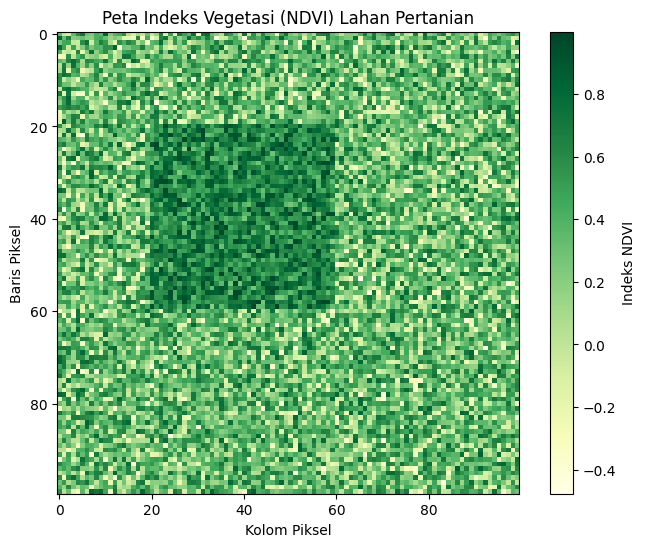

In [ ]:
# Menghitung NDVI
ndvi = (band_nir - band_red) / (band_nir + band_red)

# Visualisasi Matriks NDVI
plt.figure(figsize=(8, 6))
plt.imshow(ndvi, cmap='YlGn')
plt.colorbar(label='Indeks NDVI')
plt.title('Peta Indeks Vegetasi (NDVI) Lahan Pertanian')
plt.xlabel('Kolom Piksel')
plt.ylabel('Baris Piksel')
plt.show()

In [ ]:
# Penyiapan dataset dari nilai piksel (Red, NIR, NDVI)
X = np.column_stack((band_red.ravel(), band_nir.ravel(), ndvi.ravel()))

# Aturan batas NDVI buatan untuk ground truth (NDVI > 0.45 dianggap sawah/vegetasi rapat)
y = (ndvi.ravel() > 0.45).astype(int)

# Split data latih dan uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Melatih Model Klasifikasi
model = RandomForestClassifier(n_estimators=50, random_state=42)
model.fit(X_train, y_train)

# Evaluasi Model
y_pred = model.predict(X_test)
print("📊 --- Hasil Evaluasi Model Klasifikasi Lahan ---")
print(classification_report(y_test, y_pred, target_names=['Non-Sawah', 'Sawah/Pertanian']))

# Prediksi seluruh area lahan
land_cover_pred = model.predict(X).reshape(height, width)

📊 --- Hasil Evaluasi Model Klasifikasi Lahan ---
                 precision    recall  f1-score   support

      Non-Sawah       1.00      1.00      1.00      1740
Sawah/Pertanian       1.00      1.00      1.00      1260

       accuracy                           1.00      3000
      macro avg       1.00      1.00      1.00      3000
   weighted avg       1.00      1.00      1.00      3000



In [ ]:
import folium

# Koordinat Pusat (Bengkulu)
lat_center, lon_center = -3.7928, 102.2608

# SOLUSI: Menggunakan Basemap Esri World Street Map (Bebas API Key)
m = folium.Map(
    location=[lat_center, lon_center],
    zoom_start=13,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles &copy; Esri &mdash; Source: Esri, DeLorme, NAVTEQ, USGS, Intermap, iPC, NRCAN, Esri Japan, METI, Esri China (Hong Kong), Esri (Thailand), TomTom, 2012'
)

# Menambahkan overlay polygon area simulasi pertanian
bengkulu_farm = folium.FeatureGroup(name="Area Pertanian Berkelanjutan")

# Poligon simulasi lokasi sawah
farm_coords = [
    [-3.790, 102.255],
    [-3.790, 102.268],
    [-3.805, 102.268],
    [-3.805, 102.255]
]

folium.Polygon(
    locations=farm_coords,
    color='green',
    fill=True,
    fill_color='green',
    fill_opacity=0.4,
    popup="<b>Status:</b> Lahan Sawah Terproteksi<br><b>Klasifikasi:</b> Pertanian Berkelanjutan"
).add_to(bengkulu_farm)

bengkulu_farm.add_to(m)
folium.LayerControl().add_to(m)

print("🗺️ Peta Web Interaktif Berhasil Dibuat:")
m

🗺️ Peta Web Interaktif Berhasil Dibuat:
